In [7]:
pip install requests pandas

Note: you may need to restart the kernel to use updated packages.


In [10]:
import requests
import pandas as pd

url = "https://earthquake.usgs.gov/fdsnws/event/1/query"

all_records = []

# Retrieve data month by month
months = pd.period_range("2021-01", "2025-12", freq="M")

for month in months:

    print("Fetching:", month)

    params = {
        "starttime": str(month.start_time.date()),
        "endtime": month.end_time.strftime("%Y-%m-%dT%H:%M:%S"),
        "minmagnitude": 3,
        "format": "geojson",
        "limit": 20000
    }

    try:
        response = requests.get(
            url, params=params, timeout=60
        )
        response.raise_for_status()

        data = response.json()

        for event in data["features"]:

            properties = event["properties"]

            geometry = event.get("geometry") or {}
            coordinates = geometry.get("coordinates") or [None, None, None]

            record = {
                "id": event.get("id"),
                "time": properties.get("time"),
                "updated": properties.get("updated"),
                "latitude": coordinates[1],
                "longitude": coordinates[0],
                "depth_km": coordinates[2],
                "mag": properties.get("mag"),
                "magType": properties.get("magType"),
                "place": properties.get("place"),
                "status": properties.get("status"),
                "tsunami": properties.get("tsunami"),
                "sig": properties.get("sig"),
                "net": properties.get("net"),
                "nst": properties.get("nst"),
                "dmin": properties.get("dmin"),
                "rms": properties.get("rms"),
                "gap": properties.get("gap"),
                "magError": properties.get("magError"),
                "depthError": properties.get("depthError"),
                "magNst": properties.get("magNst"),
                "locationSource": properties.get("locationSource"),
                "magSource": properties.get("magSource"),
                "types": properties.get("types"),
                "ids": properties.get("ids"),
                "sources": properties.get("sources"),
                "type": properties.get("type")
            }

            all_records.append(record)

    except requests.exceptions.RequestException as e:
        print("Error fetching", month, ":", e)

# Convert records into DataFrame
df = pd.DataFrame(all_records)

# Convert timestamps from milliseconds to datetime
df["time"] = pd.to_datetime(
    df["time"], unit="ms", utc=True
)

df["updated"] = pd.to_datetime(
    df["updated"], unit="ms", utc=True
)

# Remove duplicate earthquake IDs
df.drop_duplicates(subset=["id"], inplace=True)

# Display results
print("Total earthquakes:", len(df))
print("Total columns:", len(df.columns))

print(df.head())

# Save dataset
df.to_csv("earthquake_data.csv", index=False)

print("Dataset saved successfully!")


Fetching: 2021-01
Fetching: 2021-02
Fetching: 2021-03
Fetching: 2021-04
Fetching: 2021-05
Fetching: 2021-06
Fetching: 2021-07
Fetching: 2021-08
Fetching: 2021-09
Fetching: 2021-10
Fetching: 2021-11
Fetching: 2021-12
Fetching: 2022-01
Fetching: 2022-02
Fetching: 2022-03
Fetching: 2022-04
Fetching: 2022-05
Fetching: 2022-06
Fetching: 2022-07
Fetching: 2022-08
Fetching: 2022-09
Fetching: 2022-10
Fetching: 2022-11
Fetching: 2022-12
Fetching: 2023-01
Fetching: 2023-02
Fetching: 2023-03
Fetching: 2023-04
Fetching: 2023-05
Fetching: 2023-06
Fetching: 2023-07
Fetching: 2023-08
Fetching: 2023-09
Fetching: 2023-10
Fetching: 2023-11
Fetching: 2023-12
Fetching: 2024-01
Fetching: 2024-02
Fetching: 2024-03
Fetching: 2024-04
Fetching: 2024-05
Fetching: 2024-06
Fetching: 2024-07
Fetching: 2024-08
Fetching: 2024-09
Fetching: 2024-10
Fetching: 2024-11
Fetching: 2024-12
Fetching: 2025-01
Fetching: 2025-02
Fetching: 2025-03
Fetching: 2025-04
Fetching: 2025-05
Fetching: 2025-06
Fetching: 2025-07
Fetching: 

In [11]:
data = pd.read_csv("earthquake_data.csv")

In [12]:
data.head()

,id,time,updated,latitude,longitude,depth_km,mag,magType,place,status,...,gap,magError,depthError,magNst,locationSource,magSource,types,ids,sources,type
0,us6000ddi8,2021-01-31 23:20:49.923000+00:00,2021-04-16 19:02:44.040000+00:00,-31.7493,-68.9337,17.27,4.7,mwr,"29 km SW of Villa Basilio Nievas, Argentina",reviewed,...,42.0,NaN,NaN,NaN,NaN,NaN,",dyfi,moment-tensor,origin,phase-data,",",us6000ddi8,",",us,",earthquake
1,us6000dev6,2021-01-31 23:08:17.161000+00:00,2021-04-16 19:03:47.040000+00:00,-15.4902,-177.2052,426.71,4.1,mb,Fiji region,reviewed,...,64.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dev6,",",us,",earthquake
2,us6000dev5,2021-01-31 22:54:19.760000+00:00,2021-04-16 19:03:47.040000+00:00,19.7529,121.3159,46.73,4.7,mb,"103 km SW of Basco, Philippines",reviewed,...,106.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dev5,",",us,",earthquake
3,us6000ddhs,2021-01-31 22:06:00.832000+00:00,2021-04-16 19:02:43.040000+00:00,28.1524,57.2570,10.00,4.9,mb,"114 km N of M?n?b, Iran",reviewed,...,71.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000ddhs,",",us,",earthquake
4,us6000dev4,2021-01-31 21:51:14.016000+00:00,2021-04-16 19:03:46.040000+00:00,71.3212,-3.7578,10.00,4.0,mb,"184 km ENE of Olonkinbyen, Svalbard and Jan Mayen",reviewed,...,65.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dev4,",",us,",earthquake


In [10]:
data.columns

Index(['id', 'time', 'updated', 'latitude', 'longitude', 'depth_km', 'mag',
       'magType', 'place', 'status', 'tsunami', 'sig', 'net', 'nst', 'dmin',
       'rms', 'gap', 'magError', 'depthError', 'magNst', 'locationSource',
       'magSource', 'types', 'ids', 'sources', 'type'],
      dtype='object')

In [13]:
data

,id,time,updated,latitude,longitude,depth_km,mag,magType,place,status,...,gap,magError,depthError,magNst,locationSource,magSource,types,ids,sources,type
0,us6000ddi8,2021-01-31 23:20:49.923000+00:00,2021-04-16 19:02:44.040000+00:00,-31.7493,-68.9337,17.270,4.7,mwr,"29 km SW of Villa Basilio Nievas, Argentina",reviewed,...,42.0,NaN,NaN,NaN,NaN,NaN,",dyfi,moment-tensor,origin,phase-data,",",us6000ddi8,",",us,",earthquake
1,us6000dev6,2021-01-31 23:08:17.161000+00:00,2021-04-16 19:03:47.040000+00:00,-15.4902,-177.2052,426.710,4.1,mb,Fiji region,reviewed,...,64.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dev6,",",us,",earthquake
2,us6000dev5,2021-01-31 22:54:19.760000+00:00,2021-04-16 19:03:47.040000+00:00,19.7529,121.3159,46.730,4.7,mb,"103 km SW of Basco, Philippines",reviewed,...,106.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dev5,",",us,",earthquake
3,us6000ddhs,2021-01-31 22:06:00.832000+00:00,2021-04-16 19:02:43.040000+00:00,28.1524,57.2570,10.000,4.9,mb,"114 km N of M?n?b, Iran",reviewed,...,71.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000ddhs,",",us,",earthquake
4,us6000dev4,2021-01-31 21:51:14.016000+00:00,2021-04-16 19:03:46.040000+00:00,71.3212,-3.7578,10.000,4.0,mb,"184 km ENE of Olonkinbyen, Svalbard and Jan Mayen",reviewed,...,65.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dev4,",",us,",earthquake
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104474,ak2025xpgfse,2025-12-01 01:51:06.974000+00:00,2026-02-25 16:18:40.040000+00:00,59.1380,-150.6400,15.200,3.2,ml,"60 km SSE of Halibut Cove, Alaska",reviewed,...,149.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us7000ret4,ak2025xpgfse,",",us,ak,",earthquake
104475,us7000ret3,2025-12-01 01:41:43.796000+00:00,2026-02-25 16:18:40.040000+00:00,7.4127,127.0704,35.000,4.6,mb,"53 km E of Baculin, Philippines",reviewed,...,96.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us7000ret3,",",us,",earthquake
104476,us7000ret2,2025-12-01 01:37:57.834000+00:00,2026-02-25 16:18:40.040000+00:00,-19.4176,-67.2761,227.844,4.1,mb,"78 km SW of Challapata, Bolivia",reviewed,...,95.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us7000ret2,",",us,",earthquake
104477,us7000resz,2025-12-01 01:25:46.725000+00:00,2026-02-25 16:18:40.040000+00:00,47.3283,-113.2019,30.159,3.1,ml,"27 km NE of Seeley Lake, Montana",reviewed,...,45.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us7000resz,",",us,",earthquake


In [14]:
print("Dataset Shape:", data.shape)
print("Total Rows:", data.shape[0])
print("Total Columns:", data.shape[1])

Dataset Shape: (104479, 26)
Total Rows: 104479
Total Columns: 26


In [15]:
print(data.columns)

Index(['id', 'time', 'updated', 'latitude', 'longitude', 'depth_km', 'mag',
       'magType', 'place', 'status', 'tsunami', 'sig', 'net', 'nst', 'dmin',
       'rms', 'gap', 'magError', 'depthError', 'magNst', 'locationSource',
       'magSource', 'types', 'ids', 'sources', 'type'],
      dtype='object')


In [16]:
print(data.dtypes)


id                 object
time               object
updated            object
latitude          float64
longitude         float64
depth_km          float64
mag               float64
magType            object
place              object
status             object
tsunami             int64
sig                 int64
net                object
nst               float64
dmin              float64
rms               float64
gap               float64
magError          float64
depthError        float64
magNst            float64
locationSource    float64
magSource         float64
types              object
ids                object
sources            object
type               object
dtype: object


In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104479 entries, 0 to 104478
Data columns (total 26 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              104479 non-null  object 
 1   time            104479 non-null  object 
 2   updated         104479 non-null  object 
 3   latitude        104479 non-null  float64
 4   longitude       104479 non-null  float64
 5   depth_km        104479 non-null  float64
 6   mag             104479 non-null  float64
 7   magType         104479 non-null  object 
 8   place           104479 non-null  object 
 9   status          104479 non-null  object 
 10  tsunami         104479 non-null  int64  
 11  sig             104479 non-null  int64  
 12  net             104479 non-null  object 
 13  nst             76718 non-null   float64
 14  dmin            100506 non-null  float64
 15  rms             104461 non-null  float64
 16  gap             101458 non-null  float64
 17  magError  

In [18]:
data.describe(include='all')

,id,time,updated,latitude,longitude,depth_km,mag,magType,place,status,...,gap,magError,depthError,magNst,locationSource,magSource,types,ids,sources,type
count,104479,104479,104479,104479.000000,104479.000000,104479.000000,104479.000000,104479,104479,104479,...,101458.000000,0.0,0.0,0.0,0.0,0.0,104479,104479,104479,104479
unique,104479,104478,28365,NaN,NaN,NaN,NaN,17,58144,2,...,NaN,NaN,NaN,NaN,NaN,NaN,538,104479,352,11
top,us6000ddi8,2021-02-27 18:59:25.296000+00:00,2025-10-17 22:51:42.040000+00:00,NaN,NaN,NaN,NaN,mb,South Sandwich Islands region,reviewed,...,NaN,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000ddi8,",",us,",earthquake
freq,1,2,1646,NaN,NaN,NaN,NaN,74318,3025,104330,...,NaN,NaN,NaN,NaN,NaN,NaN,79569,1,76582,103666
mean,NaN,NaN,NaN,11.813626,6.818629,72.043425,4.260071,NaN,NaN,NaN,...,121.825496,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,32.133593,128.865982,123.618019,0.607651,NaN,NaN,NaN,...,62.770568,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,-73.220400,-179.999700,-3.740000,3.000000,NaN,NaN,NaN,...,8.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,-14.979550,-113.917150,10.000000,4.000000,NaN,NaN,NaN,...,75.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,14.548200,22.256800,21.100000,4.300000,NaN,NaN,NaN,...,112.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,38.678450,130.378150,71.276000,4.600000,NaN,NaN,NaN,...,155.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
import pandas as pd
import numpy as np
import requests
import re
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
import os

print(os.path.abspath("earthquake_data.csv"))

C:\Users\HP\OneDrive\Desktop\Guvi-Practice - Python\earthquake_data.csv


In [22]:
data = pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\Guvi-Practice - Python\earthquake_data.csv")

In [23]:
data.head()

,id,time,updated,latitude,longitude,depth_km,mag,magType,place,status,...,gap,magError,depthError,magNst,locationSource,magSource,types,ids,sources,type
0,us6000ddi8,2021-01-31 23:20:49.923000+00:00,2021-04-16 19:02:44.040000+00:00,-31.7493,-68.9337,17.27,4.7,mwr,"29 km SW of Villa Basilio Nievas, Argentina",reviewed,...,42.0,NaN,NaN,NaN,NaN,NaN,",dyfi,moment-tensor,origin,phase-data,",",us6000ddi8,",",us,",earthquake
1,us6000dev6,2021-01-31 23:08:17.161000+00:00,2021-04-16 19:03:47.040000+00:00,-15.4902,-177.2052,426.71,4.1,mb,Fiji region,reviewed,...,64.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dev6,",",us,",earthquake
2,us6000dev5,2021-01-31 22:54:19.760000+00:00,2021-04-16 19:03:47.040000+00:00,19.7529,121.3159,46.73,4.7,mb,"103 km SW of Basco, Philippines",reviewed,...,106.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dev5,",",us,",earthquake
3,us6000ddhs,2021-01-31 22:06:00.832000+00:00,2021-04-16 19:02:43.040000+00:00,28.1524,57.2570,10.00,4.9,mb,"114 km N of M?n?b, Iran",reviewed,...,71.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000ddhs,",",us,",earthquake
4,us6000dev4,2021-01-31 21:51:14.016000+00:00,2021-04-16 19:03:46.040000+00:00,71.3212,-3.7578,10.00,4.0,mb,"184 km ENE of Olonkinbyen, Svalbard and Jan Mayen",reviewed,...,65.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dev4,",",us,",earthquake


In [24]:
print("Number of Rows:", data.shape[0])
print("Number of Columns:", data.shape[1])

Number of Rows: 104479
Number of Columns: 26


In [25]:
print(data.columns.tolist())

['id', 'time', 'updated', 'latitude', 'longitude', 'depth_km', 'mag', 'magType', 'place', 'status', 'tsunami', 'sig', 'net', 'nst', 'dmin', 'rms', 'gap', 'magError', 'depthError', 'magNst', 'locationSource', 'magSource', 'types', 'ids', 'sources', 'type']


In [26]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104479 entries, 0 to 104478
Data columns (total 26 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              104479 non-null  object 
 1   time            104479 non-null  object 
 2   updated         104479 non-null  object 
 3   latitude        104479 non-null  float64
 4   longitude       104479 non-null  float64
 5   depth_km        104479 non-null  float64
 6   mag             104479 non-null  float64
 7   magType         104479 non-null  object 
 8   place           104479 non-null  object 
 9   status          104479 non-null  object 
 10  tsunami         104479 non-null  int64  
 11  sig             104479 non-null  int64  
 12  net             104479 non-null  object 
 13  nst             76718 non-null   float64
 14  dmin            100506 non-null  float64
 15  rms             104461 non-null  float64
 16  gap             101458 non-null  float64
 17  magError  

In [27]:
data.isnull().sum()

id                     0
time                   0
updated                0
latitude               0
longitude              0
depth_km               0
mag                    0
magType                0
place                  0
status                 0
tsunami                0
sig                    0
net                    0
nst                27761
dmin                3973
rms                   18
gap                 3021
magError          104479
depthError        104479
magNst            104479
locationSource    104479
magSource         104479
types                  0
ids                    0
sources                0
type                   0
dtype: int64

In [28]:
missing_summary = pd.DataFrame({
    'Missing_Count': data.isnull().sum(),
    'Missing_Percentage': (data.isnull().sum() / len(data)) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
].sort_values(by='Missing_Percentage', ascending=False)

print(missing_summary)

                Missing_Count  Missing_Percentage
magError               104479          100.000000
depthError             104479          100.000000
magNst                 104479          100.000000
locationSource         104479          100.000000
magSource              104479          100.000000
nst                     27761           26.570890
dmin                     3973            3.802678
gap                      3021            2.891490
rms                        18            0.017228


In [29]:
# Check duplicate rows
duplicate_count = data.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


In [30]:
duplicate_ids = data['id'].duplicated().sum()

print("Duplicate Earthquake IDs:", duplicate_ids)

Duplicate Earthquake IDs: 0


In [31]:
# Convert time columns into datetime format

data['time'] = pd.to_datetime(data['time'], utc=True, errors='coerce')

data['updated'] = pd.to_datetime(data['updated'], utc=True, errors='coerce')

# Check the data types
print(data[['time', 'updated']].dtypes)

time       datetime64[ns, UTC]
updated    datetime64[ns, UTC]
dtype: object


In [32]:
print("Missing values in time:", data['time'].isnull().sum())

print("Missing values in updated:", data['updated'].isnull().sum())

Missing values in time: 171
Missing values in updated: 23


In [33]:
# Display records with missing time
invalid_time = data[data['time'].isnull()]

print("Records with invalid time:", len(invalid_time))

invalid_time.head(10)

Records with invalid time: 171


,id,time,updated,latitude,longitude,depth_km,mag,magType,place,status,...,gap,magError,depthError,magNst,locationSource,magSource,types,ids,sources,type
101,us6000dd3m,NaT,2021-04-16 19:02:22.040000+00:00,14.176300,145.1727,108.17,4.60,mb,"77 km NNE of Yigo Village, Guam",reviewed,...,46.0,NaN,NaN,NaN,NaN,NaN,",dyfi,origin,phase-data,",",us6000dd3m,",",us,",earthquake
327,us7000d34x,NaT,2021-04-13 17:07:35.040000+00:00,-11.927100,65.9579,10.00,4.70,mb,Mid-Indian Ridge,reviewed,...,56.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us7000d34x,",",us,",earthquake
1401,pr2021007008,NaT,2021-01-07 10:35:46.641000+00:00,18.095800,-68.3793,66.00,3.61,md,"39 km SE of Boca de Yuma, Dominican Republic",reviewed,...,190.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",pr2021007008,",",pr,",earthquake
1499,pr2021005089,NaT,2021-02-27 09:08:11.354000+00:00,19.035300,-65.3995,50.00,3.06,md,"80 km NNE of Luquillo, Puerto Rico",reviewed,...,306.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",pr2021005089,",",pr,",earthquake
3136,us6000dfkn,NaT,2021-04-22 21:51:30.040000+00:00,-5.381600,145.9206,71.47,5.00,mb,"23 km SE of Madang, Papua New Guinea",reviewed,...,51.0,NaN,NaN,NaN,NaN,NaN,",dyfi,origin,phase-data,",",us6000dfkn,",",us,",earthquake
3500,us6000dfvw,NaT,2021-04-16 19:03:50.040000+00:00,43.983500,84.1571,10.00,4.40,mb,"95 km NE of Xinyuan, China",reviewed,...,99.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000dfvw,",",us,",earthquake
3669,uu60430657,NaT,2021-06-08 17:58:59.040000+00:00,38.335833,-113.1005,4.99,3.23,ml,"10 km SW of Milford, Utah",reviewed,...,100.0,NaN,NaN,NaN,NaN,NaN,",dyfi,moment-tensor,origin,phase-data,shakemap,",",uu60430657,us6000dx9t,",",uu,us,",earthquake
4022,ok2021fqjl,NaT,2021-06-02 15:24:25.040000+00:00,36.113333,-98.0290,5.95,3.25,ml,"11 km W of Hennessey, Oklahoma",reviewed,...,37.0,NaN,NaN,NaN,NaN,NaN,",dyfi,moment-tensor,origin,phase-data,shakemap,",",ok2021fqjl,us7000dlij,",",ok,us,",earthquake
6521,us6000e513,NaT,2021-07-03 16:49:47.040000+00:00,-24.131400,-179.6771,491.96,4.50,mb,south of the Fiji Islands,reviewed,...,47.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000e513,",",us,",earthquake
6862,us6000e399,NaT,2021-06-19 21:26:20.040000+00:00,5.998400,-77.6362,10.00,4.30,mb,"35 km SW of Bahía Solano, Colombia",reviewed,...,111.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",us6000e399,",",us,",earthquake


In [34]:
# Display records with missing updated date
invalid_updated = data[data['updated'].isnull()]

print("Records with invalid updated:", len(invalid_updated))

invalid_updated.head(10)

Records with invalid updated: 23


,id,time,updated,latitude,longitude,depth_km,mag,magType,place,status,...,gap,magError,depthError,magNst,locationSource,magSource,types,ids,sources,type
105,us6000dd2i,2021-01-29 19:47:55.783000+00:00,NaT,-13.967200,121.864100,10.00,5.7000,mww,northwest of Australia,reviewed,...,24.0,NaN,NaN,NaN,NaN,NaN,",dyfi,internal-origin,losspager,moment-tensor,...",",us6000dd2i,pt21029001,iscgem619781797,",",us,pt,iscgem,",earthquake
3745,us6000dx01,2021-03-27 11:14:45.304000+00:00,NaT,-21.362200,171.227400,10.00,4.9000,mb,"286 km SE of Isangel, Vanuatu",reviewed,...,103.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",iscgem620185951,us6000dx01,",",iscgem,us,",earthquake
4008,us7000dljz,2021-03-22 08:18:12.149000+00:00,NaT,-28.661100,-176.454900,10.00,4.8000,mb,Kermadec Islands region,reviewed,...,80.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",iscgem620174336,us7000dljz,",",iscgem,us,",earthquake
4643,us7000divm,2021-03-12 16:00:26.317000+00:00,NaT,-33.212800,-71.890700,24.21,4.1000,mwr,"31 km SW of Valparaíso, Chile",reviewed,...,149.0,NaN,NaN,NaN,NaN,NaN,",dyfi,moment-tensor,origin,phase-data,",",us7000divm,",",us,",earthquake
10120,ew1623472898,2021-06-12 04:41:38.511000+00:00,NaT,33.235400,-115.643600,8.00,4.1407,mw,"11 km W of Niland, California",automatic,...,NaN,NaN,NaN,NaN,NaN,NaN,",associate,origin,shake-alert,",",ew1623472898,",",ew,",earthquake
11671,us7000en1d,2021-07-18 00:36:33.775000+00:00,NaT,-19.225000,-175.345600,215.53,5.4000,mww,"122 km WNW of Pangai, Tonga",reviewed,...,20.0,NaN,NaN,NaN,NaN,NaN,",losspager,origin,phase-data,shakemap,",",us7000en1d,iscgem620833218,",",us,iscgem,",earthquake
17759,us6000furk,2021-10-15 02:44:59.320000+00:00,NaT,-8.878300,158.464200,33.00,6.4000,mww,"148 km WSW of Buala, Solomon Islands",reviewed,...,20.0,NaN,NaN,NaN,NaN,NaN,",dyfi,ground-failure,impact-link,impact-text,i...",",at00r0zzn1,us6000furk,pt21288000,usauto6000fu...",",at,us,pt,usauto,iscgem,",earthquake
24016,pr71337273,2022-02-25 16:09:28.780000+00:00,NaT,17.970167,-66.743833,12.41,3.0000,md,"4 km SW of Tallaboa, Puerto Rico",reviewed,...,159.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",pr71337273,",",pr,",earthquake
32916,ci40063391,NaT,NaT,35.709167,-117.584333,6.30,4.5800,mw,"13km NE of Ridgecrest, CA",reviewed,...,43.0,NaN,NaN,NaN,NaN,NaN,",dyfi,focal-mechanism,losspager,moment-tensor,...",",ci40063391,us6000i2jx,ew1657847950,",",ci,us,ew,",earthquake
35148,pr71363128,2022-08-06 12:08:37.830000+00:00,NaT,18.906833,-65.881500,11.84,3.1000,md,"52 km N of Loíza, Puerto Rico",reviewed,...,241.0,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",pr71363128,",",pr,",earthquake


In [35]:
# Display all records with invalid earthquake time

data.loc[data['time'].isnull(), ['id', 'time', 'updated', 'place', 'mag']].head(15)

,id,time,updated,place,mag
101,us6000dd3m,NaT,2021-04-16 19:02:22.040000+00:00,"77 km NNE of Yigo Village, Guam",4.60
327,us7000d34x,NaT,2021-04-13 17:07:35.040000+00:00,Mid-Indian Ridge,4.70
1401,pr2021007008,NaT,2021-01-07 10:35:46.641000+00:00,"39 km SE of Boca de Yuma, Dominican Republic",3.61
1499,pr2021005089,NaT,2021-02-27 09:08:11.354000+00:00,"80 km NNE of Luquillo, Puerto Rico",3.06
3136,us6000dfkn,NaT,2021-04-22 21:51:30.040000+00:00,"23 km SE of Madang, Papua New Guinea",5.00
3500,us6000dfvw,NaT,2021-04-16 19:03:50.040000+00:00,"95 km NE of Xinyuan, China",4.40
3669,uu60430657,NaT,2021-06-08 17:58:59.040000+00:00,"10 km SW of Milford, Utah",3.23
4022,ok2021fqjl,NaT,2021-06-02 15:24:25.040000+00:00,"11 km W of Hennessey, Oklahoma",3.25
6521,us6000e513,NaT,2021-07-03 16:49:47.040000+00:00,south of the Fiji Islands,4.50
6862,us6000e399,NaT,2021-06-19 21:26:20.040000+00:00,"35 km SW of Bahía Solano, Colombia",4.30


In [36]:
# Display all records with invalid updated date

data.loc[data['updated'].isnull(), ['id', 'time', 'updated', 'place', 'mag']].head(15)

,id,time,updated,place,mag
105,us6000dd2i,2021-01-29 19:47:55.783000+00:00,NaT,northwest of Australia,5.7000
3745,us6000dx01,2021-03-27 11:14:45.304000+00:00,NaT,"286 km SE of Isangel, Vanuatu",4.9000
4008,us7000dljz,2021-03-22 08:18:12.149000+00:00,NaT,Kermadec Islands region,4.8000
4643,us7000divm,2021-03-12 16:00:26.317000+00:00,NaT,"31 km SW of Valparaíso, Chile",4.1000
10120,ew1623472898,2021-06-12 04:41:38.511000+00:00,NaT,"11 km W of Niland, California",4.1407
11671,us7000en1d,2021-07-18 00:36:33.775000+00:00,NaT,"122 km WNW of Pangai, Tonga",5.4000
17759,us6000furk,2021-10-15 02:44:59.320000+00:00,NaT,"148 km WSW of Buala, Solomon Islands",6.4000
24016,pr71337273,2022-02-25 16:09:28.780000+00:00,NaT,"4 km SW of Tallaboa, Puerto Rico",3.0000
32916,ci40063391,NaT,NaT,"13km NE of Ridgecrest, CA",4.5800
35148,pr71363128,2022-08-06 12:08:37.830000+00:00,NaT,"52 km N of Loíza, Puerto Rico",3.1000


In [37]:
# Create a separate working copy
clean_data = data.copy()

# Remove records with missing earthquake time
clean_data = clean_data.dropna(subset=['time'])

# Check the updated dataset
print("Original dataset rows:", len(data))
print("Cleaned dataset rows:", len(clean_data))

print("Missing values in time:", clean_data['time'].isnull().sum())
print("Missing values in updated:", clean_data['updated'].isnull().sum())

Original dataset rows: 104479
Cleaned dataset rows: 104308
Missing values in time: 0
Missing values in updated: 22


In [38]:
# Identify text columns
text_columns = clean_data.select_dtypes(include=['object']).columns

print("Text columns:")
print(text_columns.tolist())


Text columns:
['id', 'magType', 'place', 'status', 'net', 'types', 'ids', 'sources', 'type']


In [39]:
# Display sample text values
for col in text_columns:
    print("\nColumn:", col)
    print(clean_data[col].head(5).tolist())


Column: id
['us6000ddi8', 'us6000dev6', 'us6000dev5', 'us6000ddhs', 'us6000dev4']

Column: magType
['mwr', 'mb', 'mb', 'mb', 'mb']

Column: place
['29 km SW of Villa Basilio Nievas, Argentina', 'Fiji region', '103 km SW of Basco, Philippines', '114 km N of M?n?b, Iran', '184 km ENE of Olonkinbyen, Svalbard and Jan Mayen']

Column: status
['reviewed', 'reviewed', 'reviewed', 'reviewed', 'reviewed']

Column: net
['us', 'us', 'us', 'us', 'us']

Column: types
[',dyfi,moment-tensor,origin,phase-data,', ',origin,phase-data,', ',origin,phase-data,', ',origin,phase-data,', ',origin,phase-data,']

Column: ids
[',us6000ddi8,', ',us6000dev6,', ',us6000dev5,', ',us6000ddhs,', ',us6000dev4,']

Column: sources
[',us,', ',us,', ',us,', ',us,', ',us,']

Column: type
['earthquake', 'earthquake', 'earthquake', 'earthquake', 'earthquake']


In [41]:
# Import regular expressions
import re

# Remove leading and trailing spaces
for col in text_columns:
    clean_data[col] = clean_data[col].str.strip()

# Remove multiple spaces and replace them with a single space
for col in text_columns:
    clean_data[col] = clean_data[col].apply(
        lambda x: re.sub(r'\s+', ' ', x) if pd.notna(x) else x
    )

# Convert selected categorical columns to lowercase
lowercase_columns = ['magType', 'status', 'net', 'type']

for col in lowercase_columns:
    clean_data[col] = clean_data[col].str.lower()

print("Text cleaning completed!")

Text cleaning completed!


In [42]:
print(clean_data[['id', 'magType', 'place', 'status', 'net', 'type']].head(10))

             id magType                                              place  \
0    us6000ddi8     mwr        29 km SW of Villa Basilio Nievas, Argentina   
1    us6000dev6      mb                                        Fiji region   
2    us6000dev5      mb                    103 km SW of Basco, Philippines   
3    us6000ddhs      mb                            114 km N of M?n?b, Iran   
4    us6000dev4      mb  184 km ENE of Olonkinbyen, Svalbard and Jan Mayen   
5  pr2021031019      md                 76 km NNE of Luquillo, Puerto Rico   
6  pr2021031018      md                 78 km NNE of Luquillo, Puerto Rico   
7  pr2021031020      md                    82 km N of Culebra, Puerto Rico   
8    us6000dev3      mb               99 km SE of Pondaguitan, Philippines   
9    us6000dev2      mb               69 km SE of Pondaguitan, Philippines   

     status net        type  
0  reviewed  us  earthquake  
1  reviewed  us  earthquake  
2  reviewed  us  earthquake  
3  reviewed  us  eart

In [43]:
# Extract location text after the last comma

clean_data['country'] = clean_data['place'].apply(
    lambda x: x.rsplit(',', 1)[-1].strip()
    if ',' in x else 'Unknown'
)

# Display sample results
print(clean_data[['place', 'country']].head(15))

                                                place                 country
0         29 km SW of Villa Basilio Nievas, Argentina               Argentina
1                                         Fiji region                 Unknown
2                     103 km SW of Basco, Philippines             Philippines
3                             114 km N of M?n?b, Iran                    Iran
4   184 km ENE of Olonkinbyen, Svalbard and Jan Mayen  Svalbard and Jan Mayen
5                  76 km NNE of Luquillo, Puerto Rico             Puerto Rico
6                  78 km NNE of Luquillo, Puerto Rico             Puerto Rico
7                     82 km N of Culebra, Puerto Rico             Puerto Rico
8                99 km SE of Pondaguitan, Philippines             Philippines
9                69 km SE of Pondaguitan, Philippines             Philippines
10                 75 km NNE of Luquillo, Puerto Rico             Puerto Rico
11                 76 km NNE of Luquillo, Puerto Rico           

In [44]:
# Count unknown country records

unknown_count = (clean_data['country'] == 'Unknown').sum()

print("Unknown country records:", unknown_count)

print(
    "Unknown country percentage:",
    round((unknown_count / len(clean_data)) * 100, 2),
    "%"
)

Unknown country records: 19706
Unknown country percentage: 18.89 %


In [45]:
# Display unique location descriptions classified as Unknown

unknown_places = clean_data.loc[
    clean_data['country'] == 'Unknown', 'place'
].value_counts()

print(unknown_places.head(20))

place
South Sandwich Islands region       3021
Kermadec Islands region             1845
south of the Fiji Islands           1840
Fiji region                         1219
southeast of the Loyalty Islands    1055
south of the Kermadec Islands        647
Reykjanes Ridge                      609
Banda Sea                            516
Mid-Indian Ridge                     482
northern Mid-Atlantic Ridge          426
southern Mid-Atlantic Ridge          386
central Mid-Atlantic Ridge           336
Kuril Islands                        331
Mariana Islands region               316
off the coast of Oregon              310
Pacific-Antarctic Ridge              246
western Indian-Antarctic Ridge       227
West Chile Rise                      215
Carlsberg Ridge                      212
southern East Pacific Rise           195
Name: count, dtype: int64


In [46]:
# Create a separate location classification

clean_data['location_region'] = clean_data['place'].apply(
    lambda x: 'Regional Location'
    if ',' not in x
    else 'Country/ Territory'
)

# Check classification counts

print(clean_data['location_region'].value_counts())

location_region
Country/ Territory    84602
Regional Location     19706
Name: count, dtype: int64


In [47]:
# Identify numerical columns

numeric_columns = clean_data.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical columns:")
print(numeric_columns.tolist())

Numerical columns:
['latitude', 'longitude', 'depth_km', 'mag', 'tsunami', 'sig', 'nst', 'dmin', 'rms', 'gap', 'magError', 'depthError', 'magNst', 'locationSource', 'magSource']


In [48]:
# Check missing values in numerical columns

print(clean_data[numeric_columns].isnull().sum())

latitude               0
longitude              0
depth_km               0
mag                    0
tsunami                0
sig                    0
nst                27732
dmin                3956
rms                   17
gap                 3010
magError          104308
depthError        104308
magNst            104308
locationSource    104308
magSource         104308
dtype: int64


In [49]:
# Generate descriptive statistics for numerical columns

print(clean_data[numeric_columns].describe().round(2))

        latitude  longitude   depth_km        mag    tsunami        sig  \
count  104308.00  104308.00  104308.00  104308.00  104308.00  104308.00   
mean       11.80       6.89      72.10       4.26       0.01     288.05   
std        32.14     128.88     123.68       0.61       0.08      91.58   
min       -73.22    -180.00      -3.57       3.00       0.00     138.00   
25%       -15.00    -113.84      10.00       4.00       0.00     259.00   
50%        14.50      22.70      21.15       4.30       0.00     285.00   
75%        38.68     130.40      71.36       4.60       0.00     326.00   
max        87.38     180.00     681.24       8.80       1.00    2910.00   

            nst       dmin        rms        gap  magError  depthError  \
count  76576.00  100352.00  104291.00  101298.00       0.0         0.0   
mean      45.27       3.20       0.65     121.81       NaN         NaN   
std       39.38       4.47       0.26      62.74       NaN         NaN   
min        0.00       0.00  

In [50]:
# Check RMS statistics
print("RMS Median:", clean_data['rms'].median())
print("RMS Mean:", clean_data['rms'].mean())

# Display records with missing RMS
missing_rms = clean_data[clean_data['rms'].isnull()]

print("Missing RMS records:", len(missing_rms))

missing_rms[['id', 'time', 'place', 'mag', 'depth_km']]

RMS Median: 0.65
RMS Mean: 0.6547515609856516
Missing RMS records: 17


,id,time,place,mag,depth_km
1313,iscgem619646626,2021-01-09 03:38:16.140000+00:00,southeast Indian Ridge,5.0500,12.0
1764,iscgem619932863,2021-02-28 06:11:33.050000+00:00,"235 km S of Mata-Utu, Wallis and Futuna",5.1400,26.0
1769,iscgem619932856,2021-02-28 03:31:23.460000+00:00,"239 km W of Hihifo, Tonga",5.1600,26.0
2356,iscgem619900745,2021-02-17 04:57:34.290000+00:00,off the coast of Ecuador,5.0600,38.0
4506,iscgem620210242,2021-03-14 14:09:13.950000+00:00,Scotia Sea,5.1800,10.0
5134,iscgem620177767,2021-03-07 03:28:18.110000+00:00,Kermadec Islands region,5.1000,36.0
5225,iscgem619921848,2021-03-06 17:32:59.220000+00:00,Kermadec Islands region,5.5000,19.1
5477,iscgem620360384,2021-03-05 12:28:52.720000+00:00,Kermadec Islands region,5.1700,20.3
7856,iscgem620441036,2021-05-25 23:20:50.420000+00:00,southeast of Easter Island,5.2400,10.0
8193,iscgem620505071,2021-05-21 06:01:37.380000+00:00,southeast of Easter Island,5.0700,10.0


In [51]:
# Check invalid latitude values
print("Invalid latitude:",
      ((clean_data['latitude'] < -90) |
       (clean_data['latitude'] > 90)).sum())

# Check invalid longitude values
print("Invalid longitude:",
      ((clean_data['longitude'] < -180) |
       (clean_data['longitude'] > 180)).sum())

# Check negative magnitude
print("Negative magnitude:",
      (clean_data['mag'] < 0).sum())

# Check negative depth
print("Negative depth:",
      (clean_data['depth_km'] < 0).sum())

# Check zero depth
print("Zero depth:",
      (clean_data['depth_km'] == 0).sum())

Invalid latitude: 0
Invalid longitude: 0
Negative magnitude: 0
Negative depth: 101
Zero depth: 823


In [52]:
# Display negative depth records

negative_depth = clean_data[clean_data['depth_km'] < 0]

print("Negative depth records:", len(negative_depth))

negative_depth[['id', 'time', 'place', 'depth_km', 'mag']].head(10)

Negative depth records: 101


,id,time,place,depth_km,mag
740,hv72324192,2021-01-18 20:55:33.060000+00:00,"8 km N of Naalehu, Hawaii",-0.27,3.21
1318,hv72314312,2021-01-09 02:23:01.500000+00:00,"26 km E of Honaunau-Napoopoo, Hawaii",-1.46,3.15
4230,hv72388857,2021-03-18 18:27:10.500000+00:00,"20 km WNW of Volcano, Hawaii",-1.62,3.10
4232,hv72388852,2021-03-18 18:23:38.490000+00:00,"20 km WNW of Volcano, Hawaii",-2.41,3.51
4913,ci39575335,2021-03-09 00:14:59.180000+00:00,"65km NNW of Stovepipe Wells, CA",-1.36,3.21
5187,hv72375037,2021-03-06 21:17:43.250000+00:00,"28 km E of Honaunau-Napoopoo, Hawaii",-3.35,3.24
7517,hv72407937,2021-04-01 11:02:08.660000+00:00,"25 km ESE of Honaunau-Napoopoo, Hawaii",-0.92,3.12
9150,nc73581561,2021-06-30 22:19:19.600000+00:00,"7km WSW of Williams, CA",-0.27,3.17
10254,hv72513392,2021-06-09 05:13:01.410000+00:00,"26 km E of Honaunau-Napoopoo, Hawaii",-1.31,3.15
12104,nc73585466,2021-07-09 04:03:02.040000+00:00,"30km SE of Markleeville, CA",-2.09,3.30


In [53]:
# Display zero depth records

zero_depth = clean_data[clean_data['depth_km'] == 0]

print("Zero depth records:", len(zero_depth))

zero_depth[['id', 'time', 'place', 'depth_km', 'mag']].head(10)

Zero depth records: 823


,id,time,place,depth_km,mag
15,us6000ddg9,2021-01-31 18:55:06.264000+00:00,"23 km ESE of Wright, Wyoming",0.0,3.0
51,us6000ddal,2021-01-30 20:01:38.678000+00:00,"17 km E of Wright, Wyoming",0.0,3.2
164,us6000dcps,2021-01-28 18:18:48.819000+00:00,"3 km N of Mountain Iron, Minnesota",0.0,3.1
199,us6000dch1,2021-01-27 20:08:54.051000+00:00,"30 km WSW of Birney, Montana",0.0,3.2
613,us7000d1tk,2021-01-20 21:02:17.337000+00:00,"14 km E of Wright, Wyoming",0.0,3.5
738,us7000d178,2021-01-18 20:59:24.876000+00:00,"22 km ENE of Wright, Wyoming",0.0,3.0
913,us7000d0fp,2021-01-15 20:08:27.113000+00:00,"42 km SE of Wright, Wyoming",0.0,3.4
971,us7000d04d,2021-01-14 21:02:26.576000+00:00,"17 km NNE of Maeser, Utah",0.0,3.1
981,us7000d02y,2021-01-14 18:26:39.325000+00:00,"10 km N of Mountain Iron, Minnesota",0.0,3.2
1086,us6000d7ub,2021-01-12 20:01:58.855000+00:00,"32 km WSW of Birney, Montana",0.0,3.0


In [54]:
negative_depth[['id', 'time', 'place', 'depth_km', 'mag']].head(10)


,id,time,place,depth_km,mag
740,hv72324192,2021-01-18 20:55:33.060000+00:00,"8 km N of Naalehu, Hawaii",-0.27,3.21
1318,hv72314312,2021-01-09 02:23:01.500000+00:00,"26 km E of Honaunau-Napoopoo, Hawaii",-1.46,3.15
4230,hv72388857,2021-03-18 18:27:10.500000+00:00,"20 km WNW of Volcano, Hawaii",-1.62,3.10
4232,hv72388852,2021-03-18 18:23:38.490000+00:00,"20 km WNW of Volcano, Hawaii",-2.41,3.51
4913,ci39575335,2021-03-09 00:14:59.180000+00:00,"65km NNW of Stovepipe Wells, CA",-1.36,3.21
5187,hv72375037,2021-03-06 21:17:43.250000+00:00,"28 km E of Honaunau-Napoopoo, Hawaii",-3.35,3.24
7517,hv72407937,2021-04-01 11:02:08.660000+00:00,"25 km ESE of Honaunau-Napoopoo, Hawaii",-0.92,3.12
9150,nc73581561,2021-06-30 22:19:19.600000+00:00,"7km WSW of Williams, CA",-0.27,3.17
10254,hv72513392,2021-06-09 05:13:01.410000+00:00,"26 km E of Honaunau-Napoopoo, Hawaii",-1.31,3.15
12104,nc73585466,2021-07-09 04:03:02.040000+00:00,"30km SE of Markleeville, CA",-2.09,3.30


In [55]:
zero_depth[['id', 'time', 'place', 'depth_km', 'mag']].head(10)

,id,time,place,depth_km,mag
15,us6000ddg9,2021-01-31 18:55:06.264000+00:00,"23 km ESE of Wright, Wyoming",0.0,3.0
51,us6000ddal,2021-01-30 20:01:38.678000+00:00,"17 km E of Wright, Wyoming",0.0,3.2
164,us6000dcps,2021-01-28 18:18:48.819000+00:00,"3 km N of Mountain Iron, Minnesota",0.0,3.1
199,us6000dch1,2021-01-27 20:08:54.051000+00:00,"30 km WSW of Birney, Montana",0.0,3.2
613,us7000d1tk,2021-01-20 21:02:17.337000+00:00,"14 km E of Wright, Wyoming",0.0,3.5
738,us7000d178,2021-01-18 20:59:24.876000+00:00,"22 km ENE of Wright, Wyoming",0.0,3.0
913,us7000d0fp,2021-01-15 20:08:27.113000+00:00,"42 km SE of Wright, Wyoming",0.0,3.4
971,us7000d04d,2021-01-14 21:02:26.576000+00:00,"17 km NNE of Maeser, Utah",0.0,3.1
981,us7000d02y,2021-01-14 18:26:39.325000+00:00,"10 km N of Mountain Iron, Minnesota",0.0,3.2
1086,us6000d7ub,2021-01-12 20:01:58.855000+00:00,"32 km WSW of Birney, Montana",0.0,3.0


In [56]:
# Create earthquake depth categories

def categorize_depth(depth):
    if depth < 70:
        return 'Shallow'
    elif depth <= 300:
        return 'Intermediate'
    else:
        return 'Deep'

clean_data['depth_category'] = clean_data['depth_km'].apply(
    categorize_depth
)

# Check category counts

print(clean_data['depth_category'].value_counts())

depth_category
Shallow         77869
Intermediate    20248
Deep             6191
Name: count, dtype: int64


In [57]:
# Create magnitude categories

def categorize_magnitude(mag):
    if mag < 4.0:
        return 'Minor'
    elif mag < 5.0:
        return 'Light'
    elif mag < 6.0:
        return 'Moderate'
    elif mag < 7.0:
        return 'Strong'
    else:
        return 'Major'


clean_data['magnitude_category'] = clean_data['mag'].apply(
    categorize_magnitude
)

# Check category counts

print(clean_data['magnitude_category'].value_counts())

magnitude_category
Light       72308
Minor       22639
Moderate     8686
Strong        600
Major          75
Name: count, dtype: int64


In [58]:
# Extract date-related features

clean_data['year'] = clean_data['time'].dt.year

clean_data['month'] = clean_data['time'].dt.month

clean_data['day'] = clean_data['time'].dt.day

clean_data['day_of_week'] = clean_data['time'].dt.day_name()

# Display the new columns

print(clean_data[
    ['time', 'year', 'month', 'day', 'day_of_week']
].head(10))

                              time  year  month  day day_of_week
0 2021-01-31 23:20:49.923000+00:00  2021      1   31      Sunday
1 2021-01-31 23:08:17.161000+00:00  2021      1   31      Sunday
2 2021-01-31 22:54:19.760000+00:00  2021      1   31      Sunday
3 2021-01-31 22:06:00.832000+00:00  2021      1   31      Sunday
4 2021-01-31 21:51:14.016000+00:00  2021      1   31      Sunday
5 2021-01-31 21:34:54.690000+00:00  2021      1   31      Sunday
6 2021-01-31 21:26:30.180000+00:00  2021      1   31      Sunday
7 2021-01-31 21:14:31.020000+00:00  2021      1   31      Sunday
8 2021-01-31 20:57:55.804000+00:00  2021      1   31      Sunday
9 2021-01-31 20:54:42.248000+00:00  2021      1   31      Sunday


In [59]:
# Create strong earthquake indicator

clean_data['is_strong_earthquake'] = np.where(
    clean_data['mag'] >= 6.0,
    'Yes',
    'No'
)

# Check the counts

print(clean_data['is_strong_earthquake'].value_counts())

is_strong_earthquake
No     103633
Yes       675
Name: count, dtype: int64


In [60]:
# Create tsunami indicator

clean_data['tsunami_status'] = clean_data['tsunami'].map({
    1: 'Tsunami Flagged',
    0: 'Not Tsunami Flagged'
})

# Check the counts

print(clean_data['tsunami_status'].value_counts())

tsunami_status
Not Tsunami Flagged    103684
Tsunami Flagged           624
Name: count, dtype: int64


In [61]:
# Display all columns in the cleaned dataset

print("Total columns:", len(clean_data.columns))

print("\nColumn names:")
print(clean_data.columns.tolist())

Total columns: 36

Column names:
['id', 'time', 'updated', 'latitude', 'longitude', 'depth_km', 'mag', 'magType', 'place', 'status', 'tsunami', 'sig', 'net', 'nst', 'dmin', 'rms', 'gap', 'magError', 'depthError', 'magNst', 'locationSource', 'magSource', 'types', 'ids', 'sources', 'type', 'country', 'location_region', 'depth_category', 'magnitude_category', 'year', 'month', 'day', 'day_of_week', 'is_strong_earthquake', 'tsunami_status']


In [62]:
# Check missing values in newly created columns

new_columns = [
    'country',
    'location_region',
    'depth_category',
    'magnitude_category',
    'year',
    'month',
    'day',
    'day_of_week',
    'is_strong_earthquake',
    'tsunami_status'
]

print(clean_data[new_columns].isnull().sum())

country                 0
location_region         0
depth_category          0
magnitude_category      0
year                    0
month                   0
day                     0
day_of_week             0
is_strong_earthquake    0
tsunami_status          0
dtype: int64


In [63]:
# Final data-quality validation

print("Total rows:", len(clean_data))

print("Duplicate rows:", clean_data.duplicated().sum())

print("Duplicate earthquake IDs:", clean_data['id'].duplicated().sum())

print("Invalid latitude:", 
      ((clean_data['latitude'] < -90) | 
       (clean_data['latitude'] > 90)).sum())

print("Invalid longitude:", 
      ((clean_data['longitude'] < -180) | 
       (clean_data['longitude'] > 180)).sum())

print("Missing event time:", clean_data['time'].isnull().sum())

print("Missing magnitude:", clean_data['mag'].isnull().sum())

Total rows: 104308
Duplicate rows: 0
Duplicate earthquake IDs: 0
Invalid latitude: 0
Invalid longitude: 0
Missing event time: 0
Missing magnitude: 0


In [64]:
# Check missing values before treatment

missing_values = clean_data.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("Missing values before treatment:")
print(missing_values)

print("\nTotal missing values:", clean_data.isnull().sum().sum())

Missing values before treatment:
updated               22
nst                27732
dmin                3956
rms                   17
gap                 3010
magError          104308
depthError        104308
magNst            104308
locationSource    104308
magSource         104308
dtype: int64

Total missing values: 556277


In [65]:
# Compare mean and median for the first four numeric columns

columns_to_check = ['nst', 'dmin', 'rms', 'gap']

for col in columns_to_check:
    print("\nColumn:", col)
    print("Mean:", clean_data[col].mean())
    print("Median:", clean_data[col].median())
    print("Missing values:", clean_data[col].isnull().sum())


Column: nst
Mean: 45.272134872544925
Median: 32.0
Missing values: 27732

Column: dmin
Mean: 3.2010790640729447
Median: 1.816
Missing values: 3956

Column: rms
Mean: 0.6547515609856516
Median: 0.65
Missing values: 17

Column: gap
Mean: 121.80536149150176
Median: 112.0
Missing values: 3010


In [67]:
clean_data[['nst', 'dmin', 'rms', 'gap']]

,nst,dmin,rms,gap
0,NaN,0.294,0.82,42.0
1,NaN,1.471,0.29,64.0
2,NaN,3.057,0.69,106.0
3,NaN,3.330,0.61,71.0
4,NaN,6.023,0.50,65.0
...,...,...,...,...
104474,100.0,0.600,0.90,149.0
104475,74.0,1.518,1.19,96.0
104476,14.0,2.371,0.73,95.0
104477,48.0,0.293,0.53,45.0


In [68]:
clean_data[['nst', 'dmin', 'rms', 'gap']].head(10)
clean_data[['nst', 'dmin', 'rms', 'gap']].tail(10)

,nst,dmin,rms,gap
104469,21.0,3.426,1.3000,126.0
104470,20.0,15.423,1.0400,116.0
104471,14.0,0.141,0.1351,197.0
104472,44.0,4.641,0.5300,73.0
104473,14.0,0.805,1.0100,84.0
104474,100.0,0.600,0.9000,149.0
104475,74.0,1.518,1.1900,96.0
104476,14.0,2.371,0.7300,95.0
104477,48.0,0.293,0.5300,45.0
104478,51.0,0.424,0.5200,83.0


In [69]:
# Create a fresh copy from the original cleaned dataset

imputed_data = clean_data.copy()

# Columns for mean imputation

columns_to_impute = ['nst', 'dmin', 'rms', 'gap']

# Fill missing values using mean

for col in columns_to_impute:
    mean_value = imputed_data[col].mean()
    imputed_data[col] = imputed_data[col].fillna(mean_value)

# Display missing-value counts after imputation

print("Missing values after mean imputation:")

print(imputed_data[columns_to_impute].isnull().sum())

Missing values after mean imputation:
nst     0
dmin    0
rms     0
gap     0
dtype: int64


In [70]:
print("Dataset shape:", imputed_data.shape)

print("\nMissing values in each column:")
print(imputed_data.isnull().sum()[imputed_data.isnull().sum() > 0])

Dataset shape: (104308, 36)

Missing values in each column:
updated               22
magError          104308
depthError        104308
magNst            104308
locationSource    104308
magSource         104308
dtype: int64


In [72]:
# Save final cleaned dataset

output_path = r"C:\Users\HP\OneDrive\Desktop\Guvi-Practice - Python\earthquake_cleaned.csv"

imputed_data.to_csv(output_path, index=False)

print("Final cleaned dataset exported successfully!")
print("Total records:", len(imputed_data))
print("Total columns:", len(imputed_data.columns))
print("File location:", output_path)

Final cleaned dataset exported successfully!
Total records: 104308
Total columns: 36
File location: C:\Users\HP\OneDrive\Desktop\Guvi-Practice - Python\earthquake_cleaned.csv


In [2]:
# Load the exported CSV

final_data = pd.read_csv(
    r"C:\Users\HP\OneDrive\Desktop\Guvi-Practice - Python\earthquake_cleaned.csv"
)

print("Exported dataset shape:", final_data.shape)

print("\nFirst 5 records:")
display(final_data.head())

NameError: name 'pd' is not defined

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Load cleaned earthquake dataset
data = pd.read_csv("earthquake_cleaned.csv")

# Display first five records
data.head()

,id,time,updated,latitude,longitude,depth_km,mag,magType,place,status,...,country,location_region,depth_category,magnitude_category,year,month,day,day_of_week,is_strong_earthquake,tsunami_status
0,us6000ddi8,2021-01-31 23:20:49.923000+00:00,2021-04-16 19:02:44.040000+00:00,-31.7493,-68.9337,17.27,4.7,mwr,"29 km SW of Villa Basilio Nievas, Argentina",reviewed,...,Argentina,Country/ Territory,Shallow,Light,2021,1,31,Sunday,No,Not Tsunami Flagged
1,us6000dev6,2021-01-31 23:08:17.161000+00:00,2021-04-16 19:03:47.040000+00:00,-15.4902,-177.2052,426.71,4.1,mb,Fiji region,reviewed,...,Unknown,Regional Location,Deep,Light,2021,1,31,Sunday,No,Not Tsunami Flagged
2,us6000dev5,2021-01-31 22:54:19.760000+00:00,2021-04-16 19:03:47.040000+00:00,19.7529,121.3159,46.73,4.7,mb,"103 km SW of Basco, Philippines",reviewed,...,Philippines,Country/ Territory,Shallow,Light,2021,1,31,Sunday,No,Not Tsunami Flagged
3,us6000ddhs,2021-01-31 22:06:00.832000+00:00,2021-04-16 19:02:43.040000+00:00,28.1524,57.2570,10.00,4.9,mb,"114 km N of M?n?b, Iran",reviewed,...,Iran,Country/ Territory,Shallow,Light,2021,1,31,Sunday,No,Not Tsunami Flagged
4,us6000dev4,2021-01-31 21:51:14.016000+00:00,2021-04-16 19:03:46.040000+00:00,71.3212,-3.7578,10.00,4.0,mb,"184 km ENE of Olonkinbyen, Svalbard and Jan Mayen",reviewed,...,Svalbard and Jan Mayen,Country/ Territory,Shallow,Light,2021,1,31,Sunday,No,Not Tsunami Flagged


In [5]:
print("Dataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
display(data.describe())

Dataset Shape: (104308, 36)

Column Names:
['id', 'time', 'updated', 'latitude', 'longitude', 'depth_km', 'mag', 'magType', 'place', 'status', 'tsunami', 'sig', 'net', 'nst', 'dmin', 'rms', 'gap', 'magError', 'depthError', 'magNst', 'locationSource', 'magSource', 'types', 'ids', 'sources', 'type', 'country', 'location_region', 'depth_category', 'magnitude_category', 'year', 'month', 'day', 'day_of_week', 'is_strong_earthquake', 'tsunami_status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104308 entries, 0 to 104307
Data columns (total 36 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    104308 non-null  object 
 1   time                  104308 non-null  object 
 2   updated               104286 non-null  object 
 3   latitude              104308 non-null  float64
 4   longitude             104308 non-null  float64
 5   depth_km              104308 non-null  float64
 

,latitude,longitude,depth_km,mag,tsunami,sig,nst,dmin,rms,gap,magError,depthError,magNst,locationSource,magSource,year,month,day
count,104308.000000,104308.000000,104308.000000,104308.000000,104308.000000,104308.000000,104308.000000,104308.000000,104308.000000,104308.000000,0.0,0.0,0.0,0.0,0.0,104308.000000,104308.000000,104308.000000
mean,11.798667,6.888417,72.095643,4.260612,0.005982,288.052901,45.272135,3.201079,0.654752,121.805361,NaN,NaN,NaN,NaN,NaN,2023.003039,6.520852,15.502569
std,32.139141,128.880805,123.679821,0.607447,0.077114,91.584275,33.738747,4.384001,0.256997,61.826733,NaN,NaN,NaN,NaN,NaN,1.444557,3.466193,8.885984
min,-73.220400,-179.999700,-3.570000,3.000000,0.000000,138.000000,0.000000,0.000000,0.000000,8.000000,NaN,NaN,NaN,NaN,NaN,2021.000000,1.000000,1.000000
25%,-14.995350,-113.839075,10.000000,4.000000,0.000000,259.000000,24.000000,0.869750,0.490000,76.000000,NaN,NaN,NaN,NaN,NaN,2022.000000,3.000000,8.000000
50%,14.497200,22.704450,21.150000,4.300000,0.000000,285.000000,45.272135,1.918000,0.650000,115.000000,NaN,NaN,NaN,NaN,NaN,2023.000000,7.000000,15.000000
75%,38.680425,130.397950,71.357250,4.600000,0.000000,326.000000,45.272135,3.597000,0.820000,153.000000,NaN,NaN,NaN,NaN,NaN,2024.000000,9.000000,23.000000
max,87.375200,179.999400,681.238000,8.800000,1.000000,2910.000000,619.000000,62.558000,2.300000,358.180000,NaN,NaN,NaN,NaN,NaN,2025.000000,12.000000,31.000000


In [6]:
print(data[[
    "year",
    "month",
    "day",
    "day_of_week",
    "magnitude_category",
    "depth_category"
]].head())

   year  month  day day_of_week magnitude_category depth_category
0  2021      1   31      Sunday              Light        Shallow
1  2021      1   31      Sunday              Light           Deep
2  2021      1   31      Sunday              Light        Shallow
3  2021      1   31      Sunday              Light        Shallow
4  2021      1   31      Sunday              Light        Shallow


In [7]:
# Count earthquakes in each magnitude category

magnitude_counts = data["magnitude_category"].value_counts()

print(magnitude_counts)

magnitude_category
Light       72308
Minor       22639
Moderate     8686
Strong        600
Major          75
Name: count, dtype: int64


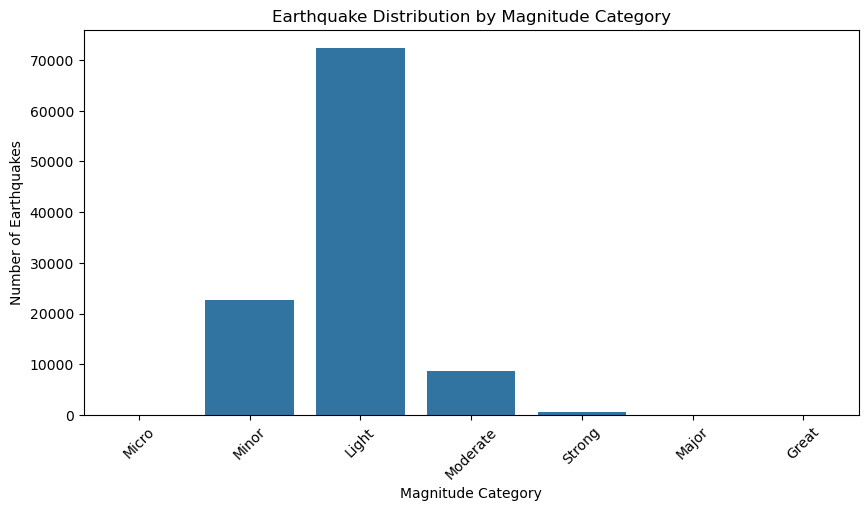

In [8]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=data,
    x="magnitude_category",
    order=["Micro", "Minor", "Light", "Moderate",
           "Strong", "Major", "Great"]
)

plt.title("Earthquake Distribution by Magnitude Category")
plt.xlabel("Magnitude Category")
plt.ylabel("Number of Earthquakes")
plt.xticks(rotation=45)

plt.show()

In [9]:
top_10 = data.nlargest(10, "mag")[
    ["id", "time", "place", "mag", "depth_km"]
]

display(top_10)

,id,time,place,mag,depth_km
92351,us6000qw60,2025-07-29 23:24:52.483000+00:00,"2025 Kamchatka Peninsula, Russia Earthquake",8.8,35.000
11072,ak0219neiszm,2021-07-29 06:15:49.188000+00:00,"2021 Chignik, Alaska Earthquake",8.2,35.000
5683,us7000dflf,2021-03-04 19:28:33.178000+00:00,"2021 Kermadec Islands, New Zealand Earthquake",8.1,28.930
14437,us6000f53e,2021-08-12 18:35:17.231000+00:00,2021 South Sandwich Islands Earthquake,8.1,22.790
45439,us6000jllz,2023-02-06 01:17:34.342000+00:00,"Pazarcik earthquake, Kahramanmaras earthquake ...",7.8,10.000
98123,us7000qx2g,2025-09-18 18:58:14.939000+00:00,"140 km E of Petropavlovsk-Kamchatsky, Russia",7.8,27.000
2999,us6000dg77,2021-02-10 13:19:55.530000+00:00,southeast of the Loyalty Islands,7.7,10.000
49784,us6000kd0n,2023-05-19 02:57:03.172000+00:00,southeast of the Loyalty Islands,7.7,18.053
85153,us7000pn9s,2025-03-28 06:20:52.715000+00:00,"2025 Mandalay, Burma (Myanmar) Earthquake",7.7,10.000
36232,us7000i9bw,2022-09-19 18:05:08.217000+00:00,"35 km SSW of Aguililla, Mexico",7.6,26.943


In [10]:
print("Maximum Magnitude:", data["mag"].max())
print("Minimum Magnitude:", data["mag"].min())
print("Average Magnitude:", data["mag"].mean())
print("Median Magnitude:", data["mag"].median())

Maximum Magnitude: 8.8
Minimum Magnitude: 3.0
Average Magnitude: 4.26061157035981
Median Magnitude: 4.3


In [11]:
print("Maximum Depth:", data["depth_km"].max())
print("Minimum Depth:", data["depth_km"].min())
print("Average Depth:", data["depth_km"].mean())
print("Median Depth:", data["depth_km"].median())

Maximum Depth: 681.238
Minimum Depth: -3.57
Average Depth: 72.09564332447896
Median Depth: 21.15


In [12]:
depth_counts = data["depth_category"].value_counts()

print(depth_counts)

depth_category
Shallow         77869
Intermediate    20248
Deep             6191
Name: count, dtype: int64


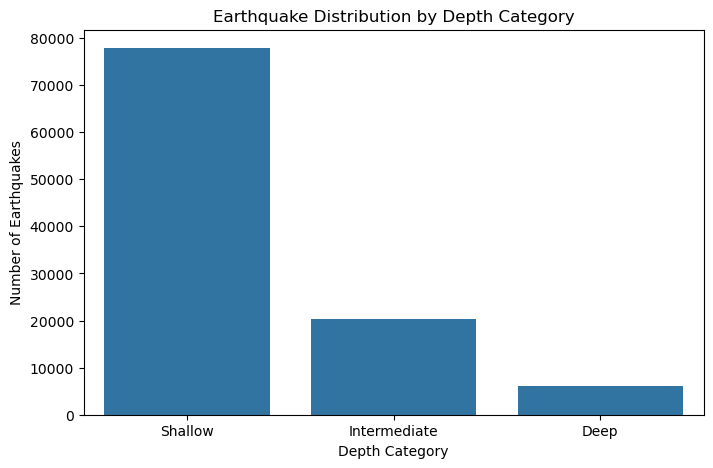

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="depth_category",
    order=["Shallow", "Intermediate", "Deep"]
)

plt.title("Earthquake Distribution by Depth Category")
plt.xlabel("Depth Category")
plt.ylabel("Number of Earthquakes")

plt.show()

In [14]:
print("Total rows:", len(data))
print("Missing depth:", data["depth_km"].isna().sum())
print("Missing depth category:", data["depth_category"].isna().sum())
print("Depth category counts including missing:")
print(data["depth_category"].value_counts(dropna=False))

Total rows: 104308
Missing depth: 0
Missing depth category: 0
Depth category counts including missing:
depth_category
Shallow         77869
Intermediate    20248
Deep             6191
Name: count, dtype: int64


In [15]:
yearly_counts = data["year"].value_counts().sort_index()

print("Year-wise Earthquake Counts:")
print(yearly_counts)

Year-wise Earthquake Counts:
year
2021    21891
2022    20176
2023    20790
2024    18627
2025    22824
Name: count, dtype: int64


Month-wise Earthquake Counts:
month
1     8875
2     8518
3     9055
4     8294
5     8142
6     7713
7     9806
8     9837
9     8341
10    8128
11    7938
12    9661
Name: count, dtype: int64


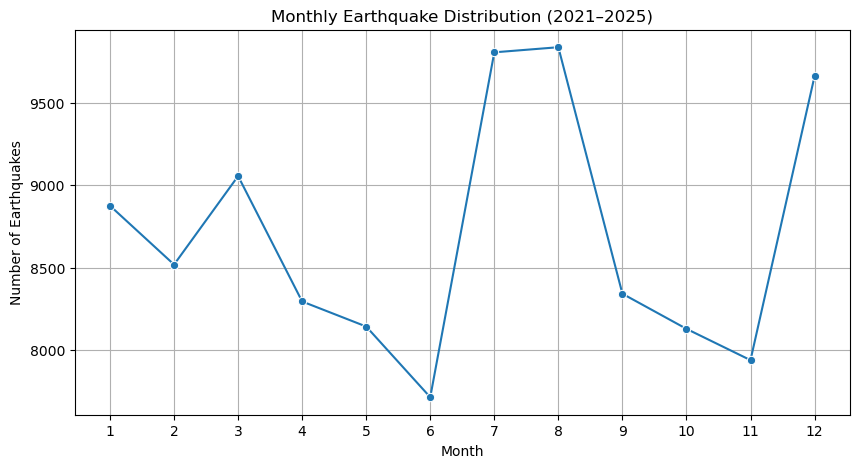

In [16]:
monthly_counts = data["month"].value_counts().sort_index()

print("Month-wise Earthquake Counts:")
print(monthly_counts)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_counts.index,
    y=monthly_counts.values,
    marker="o"
)

plt.title("Monthly Earthquake Distribution (2021–2025)")
plt.xlabel("Month")
plt.ylabel("Number of Earthquakes")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [17]:
print("Current dataset shape:", data.shape)
print("Total yearly records:", yearly_counts.sum())
print("Missing year values:", data["year"].isna().sum())

Current dataset shape: (104308, 36)
Total yearly records: 104308
Missing year values: 0


In [18]:
top_locations = (
    data["place"]
    .value_counts()
    .head(10)
)

print("Top 10 Earthquake Locations:")
print(top_locations)

Top 10 Earthquake Locations:
place
South Sandwich Islands region            3021
Kermadec Islands region                  1845
south of the Fiji Islands                1840
Fiji region                              1219
southeast of the Loyalty Islands         1055
Izu Islands, Japan region                 982
Kermadec Islands, New Zealand             860
Rat Islands, Aleutian Islands, Alaska     793
south of the Kermadec Islands             647
Reykjanes Ridge                           609
Name: count, dtype: int64


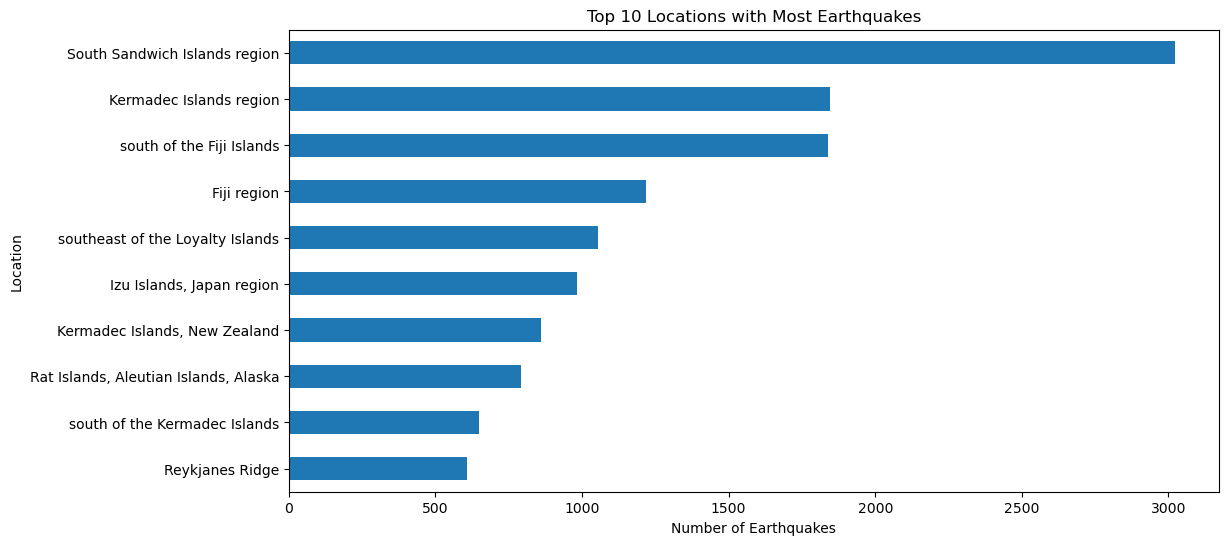

In [19]:
plt.figure(figsize=(12, 6))

top_locations.sort_values().plot(kind="barh")

plt.title("Top 10 Locations with Most Earthquakes")
plt.xlabel("Number of Earthquakes")
plt.ylabel("Location")

plt.show()

In [20]:
print(data["place"].head(20).to_string(index=False))

      29 km SW of Villa Basilio Nievas, Argentina
                                      Fiji region
                  103 km SW of Basco, Philippines
                          114 km N of M?n?b, Iran
184 km ENE of Olonkinbyen, Svalbard and Jan Mayen
               76 km NNE of Luquillo, Puerto Rico
               78 km NNE of Luquillo, Puerto Rico
                  82 km N of Culebra, Puerto Rico
             99 km SE of Pondaguitan, Philippines
             69 km SE of Pondaguitan, Philippines
               75 km NNE of Luquillo, Puerto Rico
               76 km NNE of Luquillo, Puerto Rico
                      52 km NE of Yairipok, India
              198 km SE of Sarangani, Philippines
                      82 km SSE of Lethem, Guyana
                     23 km ESE of Wright, Wyoming
               76 km NNE of Luquillo, Puerto Rico
               72 km NNE of Luquillo, Puerto Rico
               83 km NNE of Luquillo, Puerto Rico
               86 km NNE of Luquillo, Puerto Rico


In [21]:
import re

def extract_location(place):
    if pd.isna(place):
        return None

    match = re.search(r",\s*([^,]+)$", place)

    if match:
        return match.group(1).strip()

    return place.strip()

data["extracted_location"] = data["place"].apply(extract_location)

display(data[["place", "extracted_location"]].head(20))

,place,extracted_location
0,"29 km SW of Villa Basilio Nievas, Argentina",Argentina
1,Fiji region,Fiji region
2,"103 km SW of Basco, Philippines",Philippines
3,"114 km N of M?n?b, Iran",Iran
4,"184 km ENE of Olonkinbyen, Svalbard and Jan Mayen",Svalbard and Jan Mayen
5,"76 km NNE of Luquillo, Puerto Rico",Puerto Rico
6,"78 km NNE of Luquillo, Puerto Rico",Puerto Rico
7,"82 km N of Culebra, Puerto Rico",Puerto Rico
8,"99 km SE of Pondaguitan, Philippines",Philippines
9,"69 km SE of Pondaguitan, Philippines",Philippines


In [22]:
print("Top 20 extracted locations:")
print(data["extracted_location"].value_counts().head(20))

Top 20 extracted locations:
extracted_location
Alaska                           12419
Indonesia                         7837
Russia                            5681
Japan                             4507
Philippines                       4350
Papua New Guinea                  3391
South Sandwich Islands region     3021
Puerto Rico                       2988
Chile                             2863
Tonga                             2846
Vanuatu                           1956
Kermadec Islands region           1845
south of the Fiji Islands         1840
Japan region                      1778
New Zealand                       1606
CA                                1454
Argentina                         1416
Greece                            1329
Northern Mariana Islands          1308
Mexico                            1293
Name: count, dtype: int64


In [23]:
sample = data.sample(20, random_state=42)

display(sample[["place", "extracted_location"]])

,place,extracted_location
82047,"11 km N of Yujing, Taiwan",Taiwan
44603,"24 km NNE of Nurda??, Turkey",Turkey
97265,"193 km W of Abepura, Indonesia",Indonesia
3221,"13 km NNW of Iquique, Chile",Chile
59995,"74 km ESE of Masohi, Indonesia",Indonesia
28076,"Pagan region, Northern Mariana Islands",Northern Mariana Islands
42067,"24 km ENE of Cruz Bay, U.S. Virgin Islands",U.S. Virgin Islands
48680,"Hokkaido, Japan region",Japan region
22882,western Indian-Antarctic Ridge,western Indian-Antarctic Ridge
54537,"144 km WSW of Nikolski, Alaska",Alaska


In [24]:
# Remove the word 'region' from extracted locations

data["extracted_location"] = (
    data["extracted_location"]
    .str.replace(r"\s+region$", "", regex=True, flags=re.IGNORECASE)
    .str.strip()
)

print("Top 30 normalized locations:")
print(data["extracted_location"].value_counts().head(30))

Top 30 normalized locations:
extracted_location
Alaska                              12422
Indonesia                            7837
Japan                                6285
Russia                               5705
Philippines                          4350
Papua New Guinea                     3391
Puerto Rico                          3129
South Sandwich Islands               3021
Tonga                                2886
Chile                                2863
Fiji                                 2437
Vanuatu                              2057
Kermadec Islands                     1845
south of the Fiji Islands            1840
New Zealand                          1622
CA                                   1454
Argentina                            1416
Greece                               1329
Northern Mariana Islands             1308
Mexico                               1293
China                                1259
Peru                                 1249
U.S. Virgin Islands         

In [25]:
print("Total records:", len(data))

print(
    "Unique extracted locations:",
    data["extracted_location"].nunique()
)

print(
    "Missing extracted locations:",
    data["extracted_location"].isna().sum()
)

display(
    data[["place", "extracted_location"]].sample(
        20, random_state=42
    )
)

Total records: 104308
Unique extracted locations: 499
Missing extracted locations: 0


,place,extracted_location
82047,"11 km N of Yujing, Taiwan",Taiwan
44603,"24 km NNE of Nurda??, Turkey",Turkey
97265,"193 km W of Abepura, Indonesia",Indonesia
3221,"13 km NNW of Iquique, Chile",Chile
59995,"74 km ESE of Masohi, Indonesia",Indonesia
28076,"Pagan region, Northern Mariana Islands",Northern Mariana Islands
42067,"24 km ENE of Cruz Bay, U.S. Virgin Islands",U.S. Virgin Islands
48680,"Hokkaido, Japan region",Japan
22882,western Indian-Antarctic Ridge,western Indian-Antarctic Ridge
54537,"144 km WSW of Nikolski, Alaska",Alaska


In [27]:
missing_values = data.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("Columns with missing values:")
print(missing_values)

Columns with missing values:
updated               22
magError          104308
depthError        104308
magNst            104308
locationSource    104308
magSource         104308
dtype: int64


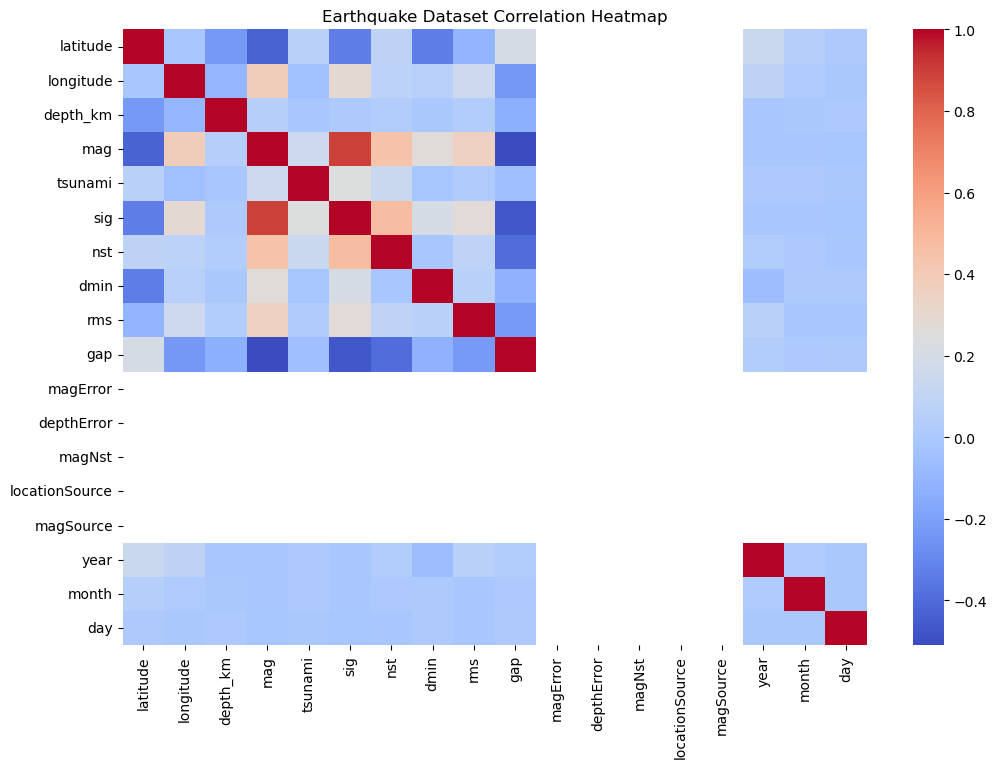

In [28]:
numeric_data = data.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Earthquake Dataset Correlation Heatmap")
plt.show()

In [29]:
print("Duplicate rows:", data.duplicated().sum())

print(
    "Duplicate earthquake IDs:",
    data["id"].duplicated().sum()
)

Duplicate rows: 0
Duplicate earthquake IDs: 0


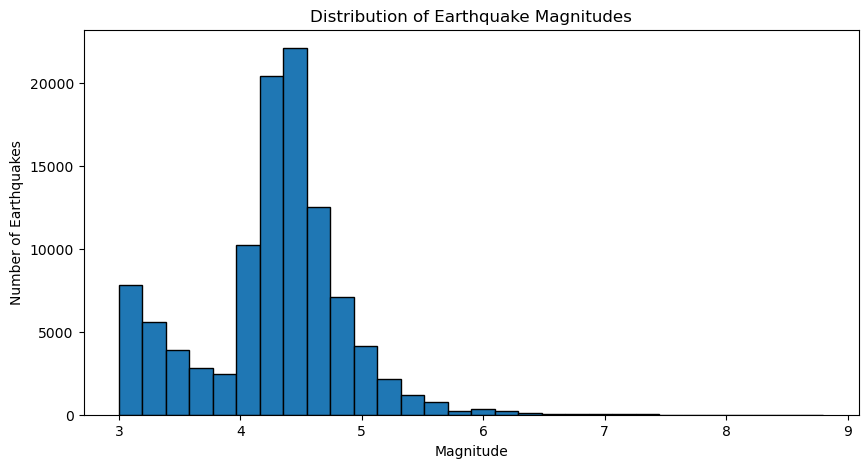

In [32]:
plt.figure(figsize=(10, 5))

plt.hist(data["mag"].dropna(), bins=30, edgecolor="black")

plt.title("Distribution of Earthquake Magnitudes")
plt.xlabel("Magnitude")
plt.ylabel("Number of Earthquakes")

plt.show()

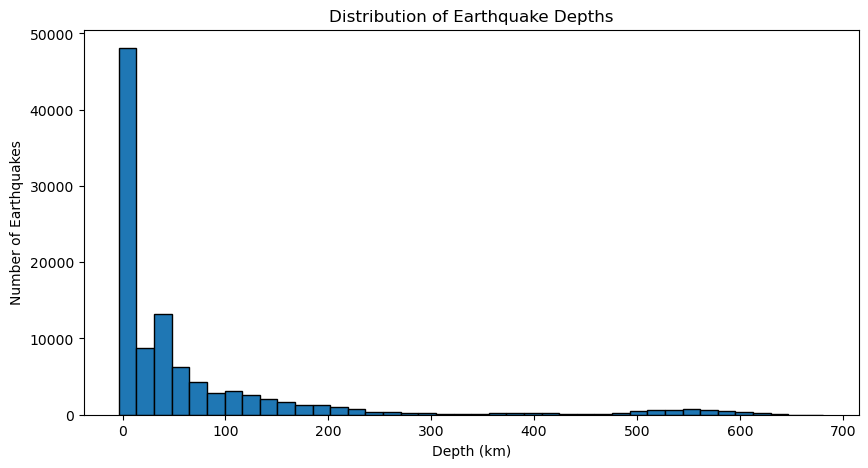

In [33]:
plt.figure(figsize=(10, 5))

plt.hist(data["depth_km"].dropna(), bins=40, edgecolor="black")

plt.title("Distribution of Earthquake Depths")
plt.xlabel("Depth (km)")
plt.ylabel("Number of Earthquakes")

plt.show()

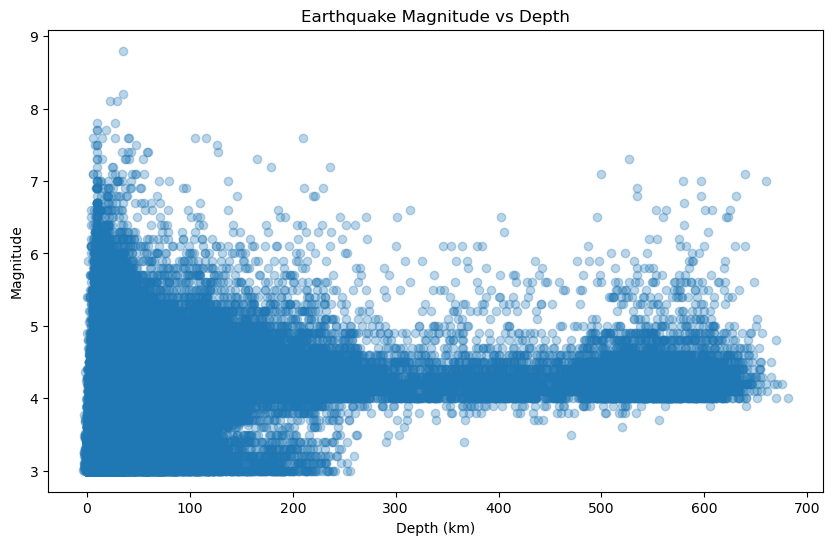

In [34]:
plt.figure(figsize=(10, 6))

plt.scatter(
    data["depth_km"],
    data["mag"],
    alpha=0.3
)

plt.title("Earthquake Magnitude vs Depth")
plt.xlabel("Depth (km)")
plt.ylabel("Magnitude")

plt.show()

tsunami
0    103684
1       624
Name: count, dtype: int64


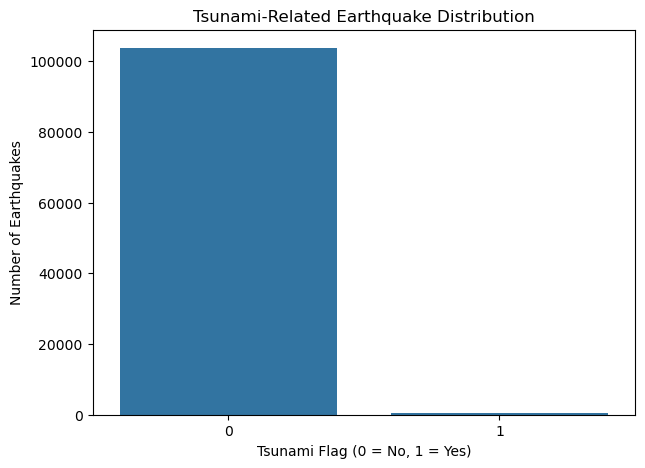

In [35]:
tsunami_counts = data["tsunami"].value_counts()

print(tsunami_counts)

plt.figure(figsize=(7, 5))

sns.countplot(data=data, x="tsunami")

plt.title("Tsunami-Related Earthquake Distribution")
plt.xlabel("Tsunami Flag (0 = No, 1 = Yes)")
plt.ylabel("Number of Earthquakes")

plt.show()